# **Logistc Regression (Nadeen)**

# Member A — Logistic Regression + Feature Engineering
Same cleaning/encoding **approach** as the original notebook — only fixed:
1. The encoder is fit **once** and reused for the feature-engineered model (no re-encoding, no second split).
2. Each part is organized into clear steps, with prints/plots showing the details at every stage.

## Step 1: Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

## Step 2: Load & Understand the Data

In [ ]:
df = pd.read_csv("aug_train.csv")

print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())

Shape: (19158, 14)

Missing values per column:
enrollee_id                  0
city                         0
city_development_index       0
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
last_new_job               423
training_hours               0
target                       0
dtype: int64


## Step 3: Handle Missing Values
- Low-missingness columns → fill with **mode**
- High-missingness columns → fill with **"Unknown"**

In [ ]:
df_clean = df.copy()

mode_columns = ["enrolled_university", "education_level", "experience", "last_new_job"]
for col in mode_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

unknown_columns = ["gender", "major_discipline", "company_size", "company_type"]
for col in unknown_columns:
    df_clean[col] = df_clean[col].fillna("Unknown")

print("Missing values after cleaning:")
print(df_clean.isnull().sum())
print("\nTotal missing values left:", df_clean.isnull().sum().sum())

Missing values after cleaning:
enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64

Total missing values left: 0


## Step 4: Define X / y and Split into Train/Test

In [ ]:
X = df_clean.drop(columns=["target", "enrollee_id"])
y = df_clean["target"]
print("X shape:", X.shape, " y shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape, " X_test:", X_test.shape)

X shape: (19158, 12)  y shape: (19158,)
X_train: (15326, 12)  X_test: (3832, 12)


## Step 5: Separate Categorical and Numerical Columns

In [ ]:
categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
numerical_columns = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical columns:", categorical_columns)
print("Numerical columns:  ", numerical_columns)

Categorical columns: ['city', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']
Numerical columns:   ['city_development_index', 'training_hours']


## Step 6: Encode Categorical Columns
This encoder is fit here a single time and **reused** later for the feature-engineered model in Step 10 — it is never re-fit.

In [ ]:
encoder = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
encoder.fit(X_train[categorical_columns])

X_train_cat = pd.DataFrame(
    encoder.transform(X_train[categorical_columns]),
    index=X_train.index, columns=encoder.get_feature_names_out(categorical_columns),
)
X_test_cat = pd.DataFrame(
    encoder.transform(X_test[categorical_columns]),
    index=X_test.index, columns=encoder.get_feature_names_out(categorical_columns),
)

X_train_encoded = pd.concat([X_train_cat, X_train[numerical_columns]], axis=1)
X_test_encoded = pd.concat([X_test_cat, X_test[numerical_columns]], axis=1)

X_train_encoded.columns = X_train_encoded.columns.astype(str)
X_test_encoded.columns = X_test_encoded.columns.astype(str)

print("X_train_encoded:", X_train_encoded.shape)
print("X_test_encoded: ", X_test_encoded.shape)

X_train_encoded: (15326, 179)
X_test_encoded:  (3832, 179)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## Step 6.1: Balance the Training Data with SMOTE
The data is imbalanced (~75% / 25%). Instead of handling this only inside individual models, we balance it **once, right here, right after encoding** — so every model trained from this point on (Logistic Regression, and later XGBoost) sees a balanced training set.


Before SMOTE: {0.0: 11504, 1.0: 3822}
After SMOTE:  {0.0: 11504, 1.0: 11504}


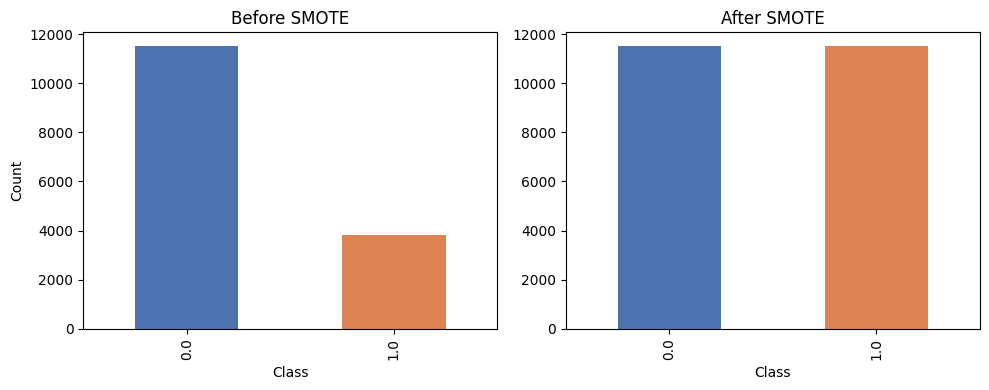

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_encoded, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_bal.value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().plot(kind="bar", ax=ax[0], color=["#4C72B0", "#DD8452"])
ax[0].set_title("Before SMOTE")
ax[0].set_xlabel("Class")
ax[0].set_ylabel("Count")
y_train_bal.value_counts().plot(kind="bar", ax=ax[1], color=["#4C72B0", "#DD8452"])
ax[1].set_title("After SMOTE")
ax[1].set_xlabel("Class")
plt.tight_layout()
plt.show()

## Step 7: Logistic Regression — Trained on SMOTE-Balanced Data
The Logistic Regression model is trained on the SMOTE-balanced training data (`X_train_bal` / `y_train_bal`). The test set remains untouched.

=== Baseline LR + SMOTE - Metrics ===
Accuracy : 0.7727035490605428
Precision: 0.5305676855895196
Recall   : 0.7633507853403141
F1-score : 0.6260197509660799


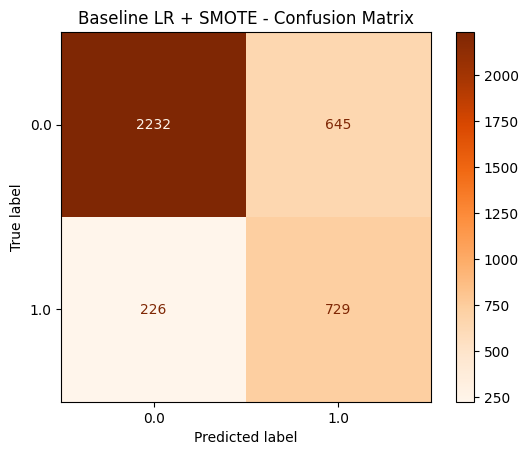

In [ ]:

model_bal = LogisticRegression(max_iter=3000)
model_bal.fit(X_train_bal, y_train_bal)

y_pred_bal = model_bal.predict(X_test_encoded)

accuracy_bal = accuracy_score(y_test, y_pred_bal)
precision_bal = precision_score(y_test, y_pred_bal)
recall_bal = recall_score(y_test, y_pred_bal)
f1_bal = f1_score(y_test, y_pred_bal)

print("=== Baseline LR + SMOTE - Metrics ===")
print("Accuracy :", accuracy_bal)
print("Precision:", precision_bal)
print("Recall   :", recall_bal)
print("F1-score :", f1_bal)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bal, cmap="Oranges")
plt.title("Baseline LR + SMOTE - Confusion Matrix")
plt.show()

## Step 8 (Bonus): Feature Engineering
Built directly on the **already-split** `X_train` / `X_test` — no new split, no new categorical column list, no new encoder.

In [ ]:
experience_num_train = X_train["experience"].replace({"<1": 0, ">20": 21, "Unknown": 0}).astype(float)
experience_num_test = X_test["experience"].replace({"<1": 0, ">20": 21, "Unknown": 0}).astype(float)

X_train_fe_num = X_train[numerical_columns].copy()
X_test_fe_num = X_test[numerical_columns].copy()

X_train_fe_num["experience_to_training_ratio"] = experience_num_train / (X_train["training_hours"] + 1)
X_test_fe_num["experience_to_training_ratio"] = experience_num_test / (X_test["training_hours"] + 1)

X_train_fe_num["has_relevant_degree"] = (X_train["major_discipline"] == "STEM").astype(int)
X_test_fe_num["has_relevant_degree"] = (X_test["major_discipline"] == "STEM").astype(int)

print("New engineered feature preview (train):")
X_train_fe_num[["experience_to_training_ratio", "has_relevant_degree"]].head(10)

New engineered feature preview (train):


,experience_to_training_ratio,has_relevant_degree
17855,0.109890,1
17664,0.312500,0
13404,0.324324,1
13366,0.092593,1
15670,0.031447,1
3857,0.137255,1
17115,0.000000,1
11516,0.400000,1
9457,1.583333,1
12825,0.020513,1


## Step 9: Build the Feature-Engineered Matrix — Reusing the Same Encoding
No re-encoding here: same one-hot columns from Step 6 (`X_train_cat` / `X_test_cat`), just extended with the two new numeric columns from Step 9.

In [ ]:
X_train_encoded_fe = pd.concat([X_train_cat, X_train_fe_num], axis=1)
X_test_encoded_fe = pd.concat([X_test_cat, X_test_fe_num], axis=1)

X_train_encoded_fe.columns = X_train_encoded_fe.columns.astype(str)
X_test_encoded_fe.columns = X_test_encoded_fe.columns.astype(str)

print("X_train_encoded_fe:", X_train_encoded_fe.shape)
print("X_test_encoded_fe: ", X_test_encoded_fe.shape)

X_train_encoded_fe: (15326, 181)
X_test_encoded_fe:  (3832, 181)


## Step 10.1: Feature-Engineered Logistic Regression — Trained on SMOTE-Balanced Data
SMOTE is applied separately here on `X_train_encoded_fe` (the feature-engineered matrix has different columns than the plain encoded one, so it needs its own balanced version, using the same `smote` settings).

=== Feature-Engineered LR + SMOTE - Metrics ===
Accuracy : 0.7802713987473904
Precision: 0.5421956684092606
Recall   : 0.7602094240837697
F1-score : 0.6329555361813426


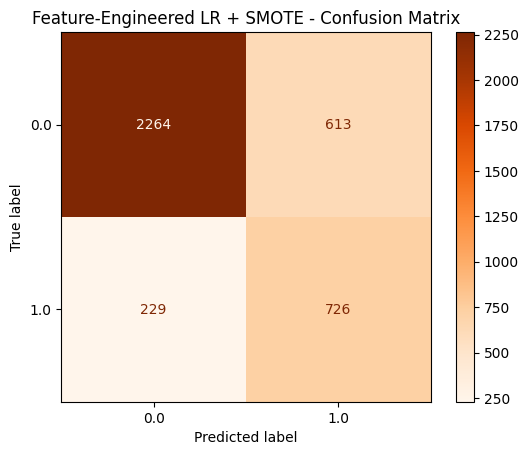

In [ ]:
X_train_fe_bal, y_train_fe_bal = smote.fit_resample(X_train_encoded_fe, y_train)

model_fe_bal = LogisticRegression(max_iter=3000)
model_fe_bal.fit(X_train_fe_bal, y_train_fe_bal)

y_pred_fe_bal = model_fe_bal.predict(X_test_encoded_fe)

accuracy_fe_bal = accuracy_score(y_test, y_pred_fe_bal)
precision_fe_bal = precision_score(y_test, y_pred_fe_bal)
recall_fe_bal = recall_score(y_test, y_pred_fe_bal)
f1_fe_bal = f1_score(y_test, y_pred_fe_bal)

print("=== Feature-Engineered LR + SMOTE - Metrics ===")
print("Accuracy :", accuracy_fe_bal)
print("Precision:", precision_fe_bal)
print("Recall   :", recall_fe_bal)
print("F1-score :", f1_fe_bal)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_fe_bal, cmap="Oranges")
plt.title("Feature-Engineered LR + SMOTE - Confusion Matrix")
plt.show()

## Step 11: Compare the Balanced Logistic Regression Models

           LR + SMOTE  FE LR + SMOTE
Accuracy     0.772704       0.780271
Precision    0.530568       0.542196
Recall       0.763351       0.760209
F1-score     0.626020       0.632956


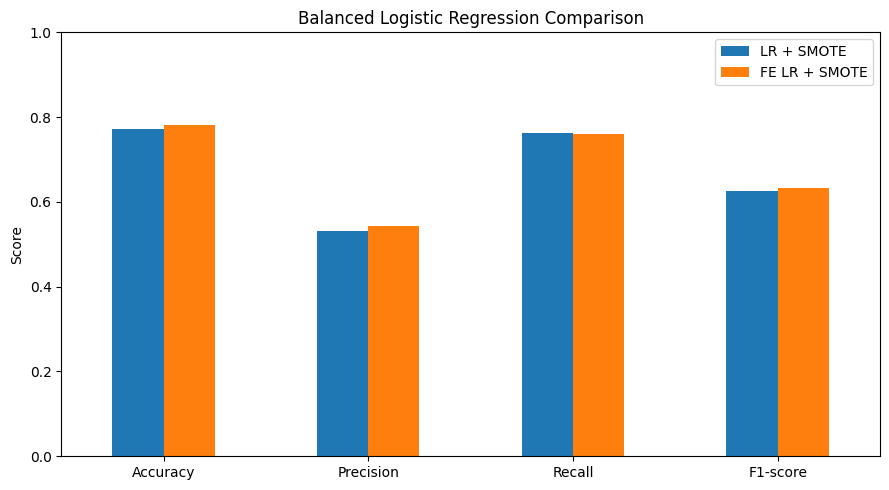

In [ ]:
comparison = pd.DataFrame({
    "LR + SMOTE": {"Accuracy": accuracy_bal, "Precision": precision_bal,
                   "Recall": recall_bal, "F1-score": f1_bal},
    "FE LR + SMOTE": {"Accuracy": accuracy_fe_bal, "Precision": precision_fe_bal,
                      "Recall": recall_fe_bal, "F1-score": f1_fe_bal},
})
print(comparison)

comparison.plot(kind="bar", figsize=(9, 5))
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Balanced Logistic Regression Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


---
# KNN (NADIA)


In [ ]:
# Baseline
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

In [ ]:
# Make column names strings
X_train_encoded.columns = X_train_encoded.columns.astype(str)
X_test_encoded.columns = X_test_encoded.columns.astype(str)

In [ ]:
#scalling
scaler = StandardScaler() # mean close to 0 and std = 1
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)


In [ ]:
print("Training mean:", X_train_scaled[:, :3].mean(axis=0).round(2))
print("Training std:", X_train_scaled[:, :3].std(axis=0).round(2))

Training mean: [-0. -0. -0.]
Training std: [1. 1. 1.]


In [ ]:
print("Training shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Training shape: (15326, 179)
Test shape: (3832, 179)


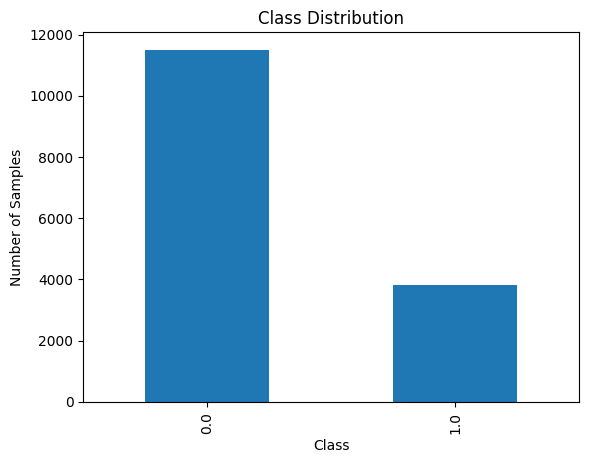

In [ ]:
import matplotlib.pyplot as plt
y_train.value_counts().plot(kind='bar')

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.show()

In [ ]:
# Test different K values and weighting methods using 5-fold cross-validation
# Uniform: all neighbors have the same effect
# Distance: closer neighbors have more effect
# Use training data only to find the best KNN settings

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [ ]:
k_range = range(1, 30, 2)
weights = ["uniform", "distance"]
# Split the data into 5 folds while keeping class proportions
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
# Test each K and weight
results = []
for weight in weights:
    for k in k_range:
        print(f"Testing K={k}, weights={weight}")

        model = KNeighborsClassifier(
            n_neighbors=k,
            weights=weight
        )
        scores = cross_val_score(
            model,
            X_train_scaled,
            y_train,
            cv=cv,
            scoring="accuracy"
        )
        results.append([k, weight, scores.mean()])

Testing K=1, weights=uniform
Testing K=3, weights=uniform
Testing K=5, weights=uniform
Testing K=7, weights=uniform
Testing K=9, weights=uniform
Testing K=11, weights=uniform
Testing K=13, weights=uniform
Testing K=15, weights=uniform
Testing K=17, weights=uniform
Testing K=19, weights=uniform
Testing K=21, weights=uniform
Testing K=23, weights=uniform
Testing K=25, weights=uniform
Testing K=27, weights=uniform
Testing K=29, weights=uniform
Testing K=1, weights=distance
Testing K=3, weights=distance
Testing K=5, weights=distance
Testing K=7, weights=distance
Testing K=9, weights=distance
Testing K=11, weights=distance
Testing K=13, weights=distance
Testing K=15, weights=distance
Testing K=17, weights=distance
Testing K=19, weights=distance
Testing K=21, weights=distance
Testing K=23, weights=distance
Testing K=25, weights=distance
Testing K=27, weights=distance
Testing K=29, weights=distance


In [ ]:
cv_results_df = pd.DataFrame(
    results,
    columns=["K", "Weights", "Accuracy"]
)

cv_results_df.T.style.hide(axis="columns")

K,1,3,5,7,9,11,13,15,17,19,21,23,25,27,29,1,3,5,7,9,11,13,15,17,19,21,23,25,27,29
Weights,uniform,uniform,uniform,uniform,uniform,uniform,uniform,uniform,uniform,uniform,uniform,uniform,uniform,uniform,uniform,distance,distance,distance,distance,distance,distance,distance,distance,distance,distance,distance,distance,distance,distance,distance
Accuracy,0.705664,0.744617,0.761712,0.763735,0.769347,0.771826,0.772544,0.773392,0.773523,0.772805,0.775741,0.776067,0.774828,0.774762,0.774828,0.705664,0.740311,0.756362,0.758058,0.762757,0.765563,0.766933,0.767781,0.767976,0.767781,0.767716,0.768238,0.768564,0.768564,0.768890


In [ ]:
best = cv_results_df.loc[cv_results_df["Accuracy"].idxmax()]
print("Best K:", best["K"])
print("Best weights:", best["Weights"])
print("Best accuracy:", best["Accuracy"])

Best K: 23
Best weights: uniform
Best accuracy: 0.7760674194368802


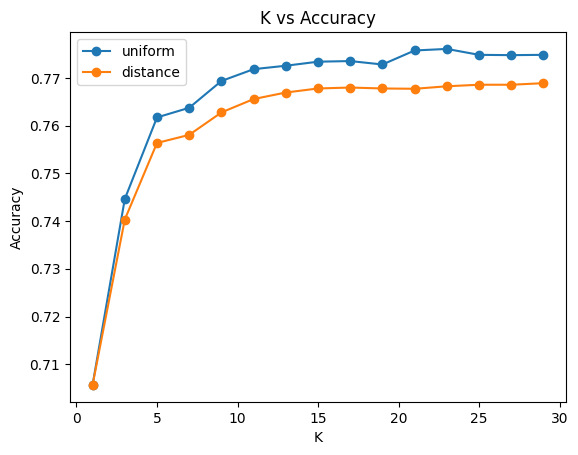

In [ ]:
# Compare K values and weighting methods
import matplotlib.pyplot as plt

for weight in weights:
    data = cv_results_df[cv_results_df["Weights"] == weight]
    plt.plot(data["K"], data["Accuracy"], marker="o", label=weight)

plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy")
plt.legend()
plt.show()

In [ ]:
#final model train with best k=23
model = KNeighborsClassifier(n_neighbors=23, weights="uniform")
model.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=23)

In [ ]:
# final test
y_pred = model.predict(X_test_scaled)

In [ ]:
# Show predictions
for prediction in y_pred[:10]:
    if prediction == 1:
        print("1 - Looking for a job change")
    else:
        print("0 - Not looking for a job change")

0 - Not looking for a job change
0 - Not looking for a job change
0 - Not looking for a job change
0 - Not looking for a job change
0 - Not looking for a job change
1 - Looking for a job change
0 - Not looking for a job change
0 - Not looking for a job change
0 - Not looking for a job change
0 - Not looking for a job change


In [ ]:
# Evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))

Accuracy: 0.7849686847599165
Precision: 0.5923836389280677
Recall: 0.4397905759162304
F1-score: 0.5048076923076923


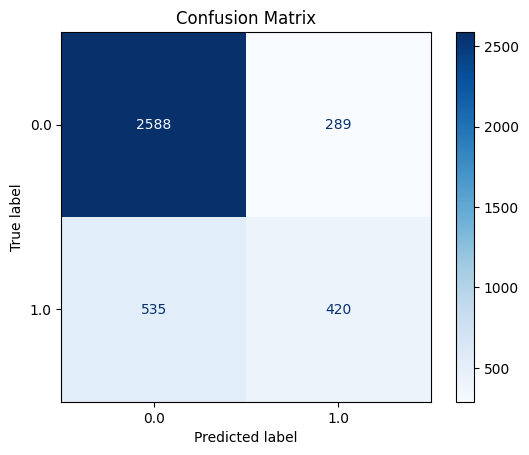

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

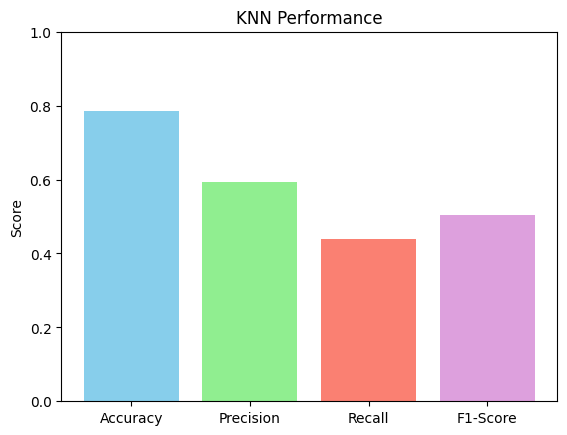

In [ ]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred)
}

plt.bar(metrics.keys(), metrics.values(), color=["skyblue", "lightgreen", "salmon", "plum"])

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("KNN Performance")
plt.show()

In [ ]:
best_cv_accuracy = max(scores)
test_accuracy = accuracy_score(y_test, y_pred)
print("CV Accuracy:", best_cv_accuracy)
print("Test Accuracy:", test_accuracy)

CV Accuracy: 0.7765089722675367
Test Accuracy: 0.7849686847599165


# Improved KNN ( Final )

In [ ]:
from sklearn.decomposition import PCA

from sklearn.model_selection import RandomizedSearchCV, cross_val_predict

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    classification_report
)

from imblearn.pipeline import Pipeline as ImbPipeline

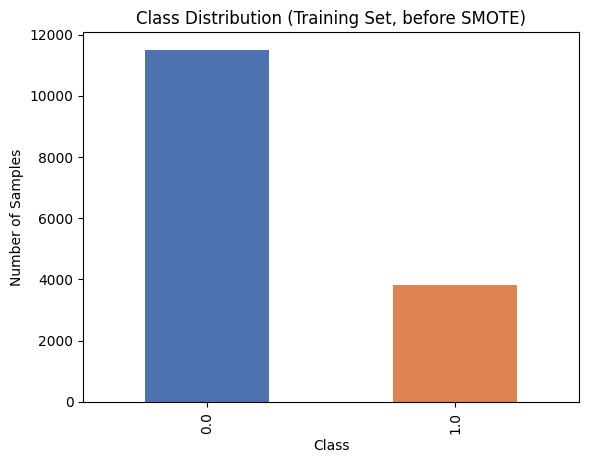

In [ ]:
y_train.value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("Class Distribution (Training Set, before SMOTE)")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.show()

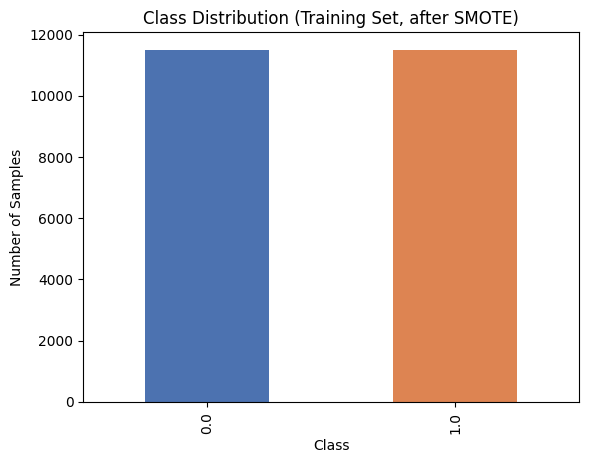

In [ ]:
# Class distribution after SMOTE
y_train_bal.value_counts().plot(
    kind="bar",
    color=["#4C72B0", "#DD8452"]
)

plt.title("Class Distribution (Training Set, after SMOTE)")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.show()

In [ ]:
knn_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("pca", PCA(random_state=42)),
    ("knn", KNeighborsClassifier(n_jobs=-1)),
])

cv_knn = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
param_distributions = {
    #try different pca values or pass without pca
    "pca": [
        PCA(n_components=0.90, random_state=42),
        PCA(n_components=0.95, random_state=42),
        PCA(n_components=0.99, random_state=42),
        "passthrough",
    ],
    "knn__n_neighbors": list(range(3, 41, 2)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

knn_search = RandomizedSearchCV(
    knn_pipeline,
    param_distributions=param_distributions, # param from dic
    n_iter=5, # 5 random combinations only
    scoring="f1",
    cv=cv_knn,
    random_state=42,
    n_jobs=-1, # best cpu
    verbose=1, # progress
)

knn_search.fit(X_train_encoded, y_train)

print("Best parameters found:")
for k, v in knn_search.best_params_.items():
    print(f"  {k}: {v}")

print("\nBest CV F1-score:", round(knn_search.best_score_, 4))

best_knn = knn_search.best_estimator_ # returns the best pipeline

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best parameters found:
  pca: passthrough
  knn__weights: distance
  knn__p: 1
  knn__n_neighbors: 33

Best CV F1-score: 0.5701


In [ ]:
cv_results_knn = pd.DataFrame(knn_search.cv_results_).sort_values("rank_test_score")

cv_results_knn[[
    "param_knn__n_neighbors",
    "param_knn__weights",
    "param_knn__p", # 1 or 2
    "param_pca",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].head(10)

,param_knn__n_neighbors,param_knn__weights,param_knn__p,param_pca,mean_test_score,std_test_score,rank_test_score
3,33,distance,1,passthrough,0.570107,0.014044,1
1,21,uniform,2,"PCA(n_components=0.99, random_state=42)",0.518003,0.011124,2
2,15,distance,2,passthrough,0.507314,0.011778,3
4,9,distance,2,"PCA(n_components=0.9, random_state=42)",0.500369,0.014225,4
0,25,distance,1,"PCA(n_components=0.9, random_state=42)",0.491860,0.010812,5


In [ ]:
y_proba_knn = best_knn.predict_proba(X_test_encoded)[:, 1] # returns proba of class 1

y_pred_knn_default = (y_proba_knn >= 0.5).astype(int) # 0 or 1
# turns probabilities into predicted classes
print("=== Tuned KNN (default 0.5 threshold) - Test Metrics ===")

print("Accuracy :", accuracy_score(y_test, y_pred_knn_default))
print("Precision:", precision_score(y_test, y_pred_knn_default))
print("Recall   :", recall_score(y_test, y_pred_knn_default))
print("F1-score :", f1_score(y_test, y_pred_knn_default))

=== Tuned KNN (default 0.5 threshold) - Test Metrics ===
Accuracy : 0.7343423799582464
Precision: 0.4795852235904083
Recall   : 0.774869109947644
F1-score : 0.5924739791833467


=== Final Tuned KNN (SMOTE + PCA + RandomizedSearchCV + Threshold Tuning) - Test Metrics ===
Accuracy : 0.7627870563674322
Precision: 0.5174506828528073
Recall   : 0.7141361256544503
F1-score : 0.6000879894412671

Full classification report:
               precision    recall  f1-score   support

         0.0       0.89      0.78      0.83      2877
         1.0       0.52      0.71      0.60       955

    accuracy                           0.76      3832
   macro avg       0.70      0.75      0.72      3832
weighted avg       0.80      0.76      0.77      3832



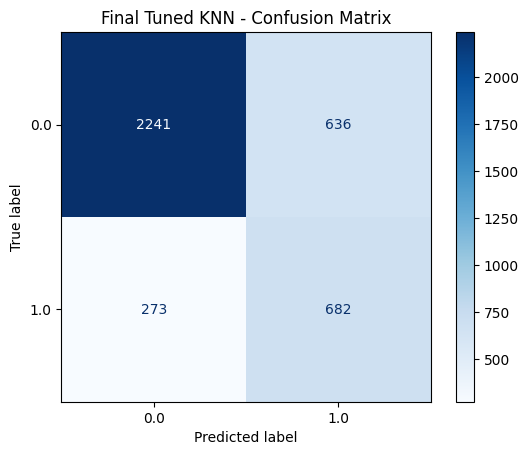

In [ ]:
y_pred = (y_proba_knn >= best_threshold).astype(int)
# returns 0 or 1
accuracy_knn = accuracy_score(y_test, y_pred)
precision_knn = precision_score(y_test, y_pred)
recall_knn = recall_score(y_test, y_pred) # based on class 1
f1_knn = f1_score(y_test, y_pred)

print("=== Final Tuned KNN (SMOTE + PCA + RandomizedSearchCV + Threshold Tuning) - Test Metrics ===")

print("Accuracy :", accuracy_knn)
print("Precision:", precision_knn)
print("Recall   :", recall_knn)
print("F1-score :", f1_knn)

print("\nFull classification report:\n", classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Final Tuned KNN - Confusion Matrix")
plt.show()

In [ ]:
# Show a few predictions, same style as the original notebook
for prediction in y_pred[:10]:
    if prediction == 1:
        print("1 - Looking for a job change")
    else:
        print("0 - Not looking for a job change")

0 - Not looking for a job change
1 - Looking for a job change
0 - Not looking for a job change
0 - Not looking for a job change
0 - Not looking for a job change
1 - Looking for a job change
0 - Not looking for a job change
0 - Not looking for a job change
1 - Looking for a job change
0 - Not looking for a job change


           Original KNN\n(k=23, no SMOTE)  \
Accuracy                         0.784969   
Precision                        0.592384   
Recall                           0.439791   
F1-score                         0.504808   

           Tuned KNN\n(SMOTE+PCA+Search+Threshold)  
Accuracy                                  0.762787  
Precision                                 0.517451  
Recall                                    0.714136  
F1-score                                  0.600088  


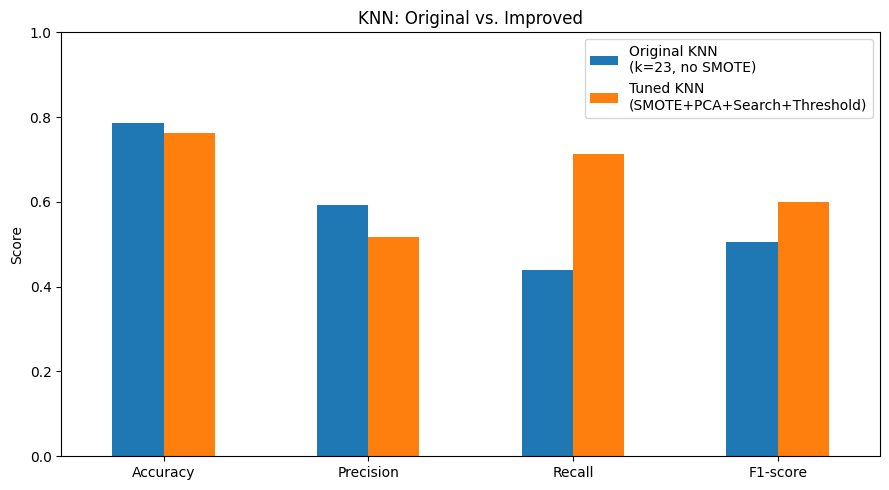

In [ ]:
comparison_knn = pd.DataFrame({
    "Original KNN\n(k=23, no SMOTE)": {
        "Accuracy": 0.784969,
        "Precision": 0.592384,
        "Recall": 0.439791,
        "F1-score": 0.504808
    },
    "Tuned KNN\n(SMOTE+PCA+Search+Threshold)": {
        "Accuracy": accuracy_knn,
        "Precision": precision_knn,
        "Recall": recall_knn,
        "F1-score": f1_knn
    },
})

print(comparison_knn)

comparison_knn.plot(kind="bar", figsize=(9, 5))
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("KNN: Original vs. Improved")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# **Random Forest (Mariam)**

In [ ]:
# Build a separate exploration DataFrame from the cleaned data.
# This uses the same feature-engineering logic as the modeling section.
df_fe = df_clean.copy()

df_fe["experience_numeric"] = (
    df_fe["experience"]
    .replace({"<1": 0, ">20": 21, "Unknown": 0})
    .astype(float)
)

df_fe["experience_to_training_ratio"] = (
    df_fe["experience_numeric"] / (df_fe["training_hours"] + 1)
)

df_fe["has_relevant_degree"] = (
    df_fe["major_discipline"] == "STEM"
).astype(int)

## Feature Engineering Exploration

In [ ]:
feature_cols = [
    "experience_to_training_ratio",
    "has_relevant_degree",
    "experience_numeric",
    "training_hours",
    "city_development_index"
]

df_fe[feature_cols].describe()

,experience_to_training_ratio,has_relevant_degree,experience_numeric,training_hours,city_development_index
count,19158.000000,19158.000000,19158.000000,19158.000000,19158.000000
mean,0.366846,0.756446,10.137123,65.366896,0.828848
std,0.606899,0.429238,6.795143,60.058462,0.123362
min,0.000000,0.000000,0.000000,1.000000,0.448000
25%,0.069948,1.000000,4.000000,23.000000,0.740000
50%,0.172414,1.000000,9.000000,47.000000,0.903000
75%,0.400000,1.000000,16.000000,88.000000,0.920000
max,10.500000,1.000000,21.000000,336.000000,0.949000


In [ ]:
df_fe[
    [
        "experience",
        "experience_numeric",
        "training_hours",
        "experience_to_training_ratio",
        "major_discipline",
        "has_relevant_degree"
    ]
].head(10)

,experience,experience_numeric,training_hours,experience_to_training_ratio,major_discipline,has_relevant_degree
0,>20,21.0,36,0.567568,STEM,1
1,15,15.0,47,0.312500,STEM,1
2,5,5.0,83,0.059524,STEM,1
3,<1,0.0,52,0.000000,Business Degree,0
4,>20,21.0,8,2.333333,STEM,1
5,11,11.0,24,0.440000,STEM,1
6,5,5.0,24,0.200000,Unknown,0
7,13,13.0,18,0.684211,STEM,1
8,7,7.0,46,0.148936,STEM,1
9,17,17.0,123,0.137097,STEM,1


In [ ]:
target_feature_analysis = df_fe[
    [
        "experience_to_training_ratio",
        "has_relevant_degree",
        "training_hours",
        "city_development_index",
        "target"
    ]
].groupby("target").mean()

target_feature_analysis

,experience_to_training_ratio,has_relevant_degree,training_hours,city_development_index
target,,,,
0.0,0.391163,0.744107,66.113761,0.853139
1.0,0.293641,0.793594,63.118484,0.755719


In [ ]:
degree_analysis = (
    df_fe.groupby("has_relevant_degree")["target"]
    .mean()
    .reset_index()
)
degree_analysis["Job_Change_Rate"] = (
    degree_analysis["target"] * 100
)

degree_analysis

,has_relevant_degree,target,Job_Change_Rate
0,0,0.211316,21.13159
1,1,0.261593,26.15926


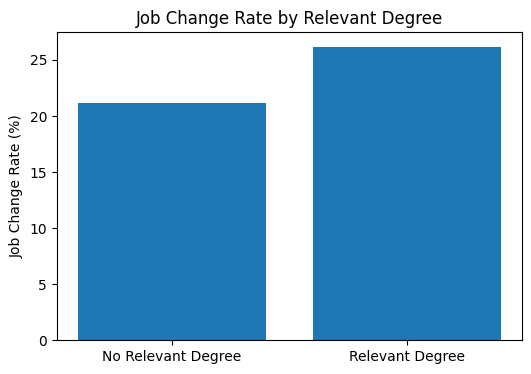

In [ ]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["No Relevant Degree", "Relevant Degree"],
    degree_analysis["Job_Change_Rate"]
)

plt.ylabel("Job Change Rate (%)")
plt.title("Job Change Rate by Relevant Degree")

plt.show()

In [ ]:
experience_analysis = (
    df_fe.groupby("experience_numeric")["target"]
    .mean()
    .reset_index()
)

experience_analysis["Job_Change_Rate"] = (
    experience_analysis["target"] * 100
)

experience_analysis.head(15)

,experience_numeric,target,Job_Change_Rate
0,0.0,0.454023,45.402299
1,1.0,0.424408,42.440801
2,2.0,0.331854,33.185448
3,3.0,0.353028,35.302806
4,4.0,0.325731,32.573058
5,5.0,0.288112,28.811189
6,6.0,0.282072,28.207237
7,7.0,0.294747,29.474708
8,8.0,0.243142,24.314214
9,9.0,0.217347,21.734694


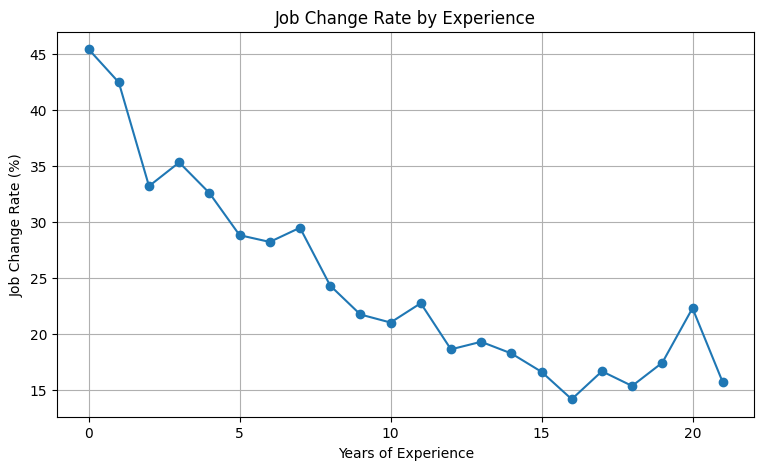

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    experience_analysis["experience_numeric"],
    experience_analysis["Job_Change_Rate"],
    marker="o"
)

plt.xlabel("Years of Experience")
plt.ylabel("Job Change Rate (%)")
plt.title("Job Change Rate by Experience")

plt.grid(True)
plt.show()

In [ ]:
training_analysis = (
    df_fe.groupby("target")["training_hours"]
    .mean()
)

training_analysis

,training_hours
target,
0.0,66.113761
1.0,63.118484


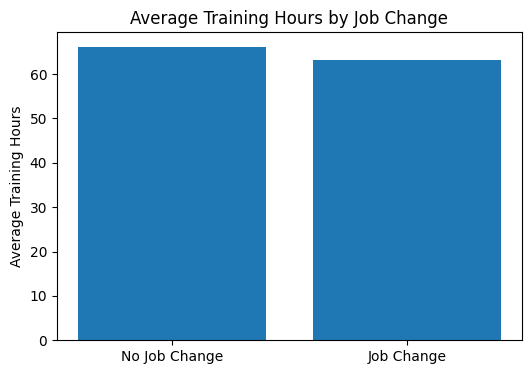

In [ ]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["No Job Change", "Job Change"],
    training_analysis.values
)

plt.ylabel("Average Training Hours")
plt.title("Average Training Hours by Job Change")

plt.show()

In [ ]:
city_analysis = (
    df_fe.groupby("target")[
        "city_development_index"
    ].mean()
)

city_analysis

,city_development_index
target,
0.0,0.853139
1.0,0.755719


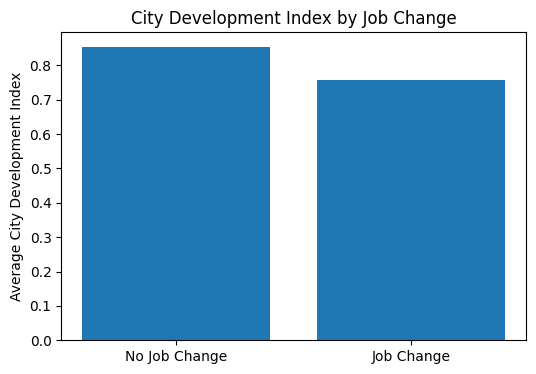

In [ ]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["No Job Change", "Job Change"],
    city_analysis.values
)

plt.ylabel("Average City Development Index")
plt.title(
    "City Development Index by Job Change"
)

plt.show()

In [ ]:
numerical_analysis = df_fe[
    [
        "city_development_index",
        "training_hours",
        "experience_numeric",
        "experience_to_training_ratio",
        "has_relevant_degree",
        "target"
    ]
]

correlation_matrix = numerical_analysis.corr()

correlation_matrix

,city_development_index,training_hours,experience_numeric,experience_to_training_ratio,has_relevant_degree,target
city_development_index,1.000000,0.001920,0.329124,0.128177,-0.075709,-0.341665
training_hours,0.001920,1.000000,0.001479,-0.389858,-0.004710,-0.021577
experience_numeric,0.329124,0.001479,1.000000,0.405932,0.159851,-0.174256
experience_to_training_ratio,0.128177,-0.389858,0.405932,1.000000,0.073797,-0.069522
has_relevant_degree,-0.075709,-0.004710,0.159851,0.073797,1.000000,0.049881
target,-0.341665,-0.021577,-0.174256,-0.069522,0.049881,1.000000


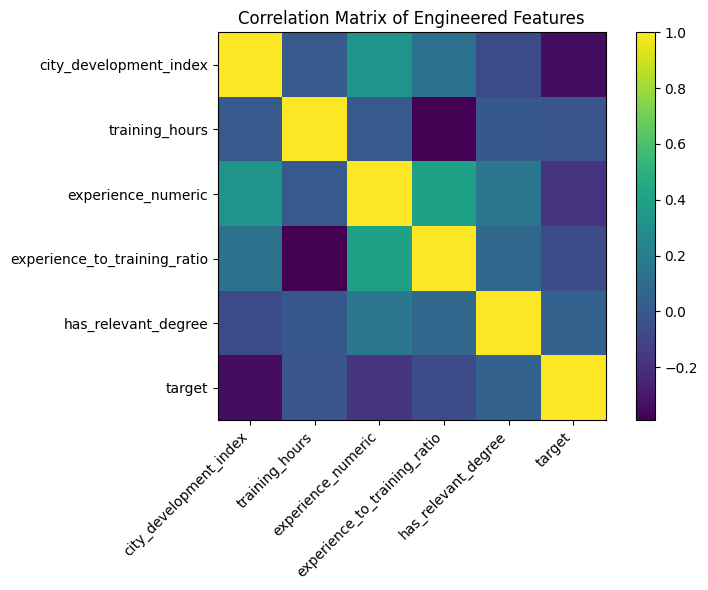

In [ ]:
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix of Engineered Features")

plt.tight_layout()
plt.show()

# 6. Random Forest

Random Forest is used to predict whether a candidate is likely to change jobs.

The model is trained using the cleaned and feature-engineered dataset.
The engineered features provide additional information about the candidate's
experience, training, and educational background.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
baseline_rf = RandomForestClassifier(
    n_estimators=200,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

baseline_rf.fit(
    X_train_encoded_fe,
    y_train
)

baseline_pred = baseline_rf.predict(
    X_test_encoded_fe
)

print("Random Forest training completed.")

Random Forest training completed.


In [ ]:
rf_accuracy = accuracy_score(y_test,baseline_pred)

rf_precision = precision_score(y_test,baseline_pred,zero_division=0)

rf_recall = recall_score(y_test,baseline_pred,zero_division=0)

rf_f1 = f1_score(y_test,baseline_pred,zero_division=0)

print("Random Forest Performance")
print("-------------------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-score : {rf_f1:.4f}")

Random Forest Performance
-------------------------
Accuracy : 0.8001
Precision: 0.5763
Recall   : 0.7476
F1-score : 0.6509


In [ ]:
print(classification_report(y_test,baseline_pred,zero_division=0))

              precision    recall  f1-score   support

         0.0       0.91      0.82      0.86      2877
         1.0       0.58      0.75      0.65       955

    accuracy                           0.80      3832
   macro avg       0.74      0.78      0.76      3832
weighted avg       0.82      0.80      0.81      3832



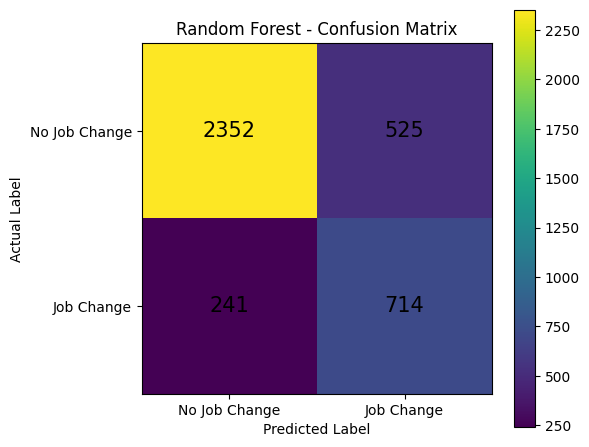

In [ ]:
cm = confusion_matrix(
    y_test,
    baseline_pred
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Random Forest - Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["No Job Change", "Job Change"]
)

plt.yticks(
    [0, 1],
    ["No Job Change", "Job Change"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=15
        )

plt.colorbar()

plt.tight_layout()
plt.show()

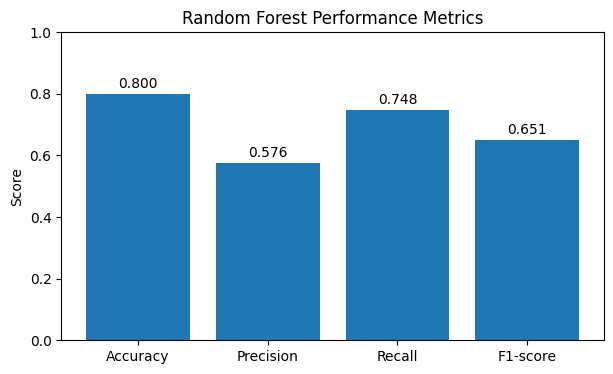

In [ ]:
rf_metrics = {
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1-score": rf_f1
}

plt.figure(figsize=(7, 4))

bars = plt.bar(
    rf_metrics.keys(),
    rf_metrics.values()
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Random Forest Performance Metrics")

for bar, value in zip(
    bars,
    rf_metrics.values()
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.show()

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X_train_encoded_fe.columns,
    "Importance": baseline_rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance.head(10)

,Feature,Importance
177,city_development_index,0.172664
62,city_city_21,0.085030
179,experience_to_training_ratio,0.079410
178,training_hours,0.072645
165,company_size_Unknown,0.068269
171,company_type_Unknown,0.044118
170,company_type_Pvt Ltd,0.026335
124,relevent_experience_No relevent experience,0.019776
126,enrolled_university_no_enrollment,0.017778
4,city_city_103,0.015464


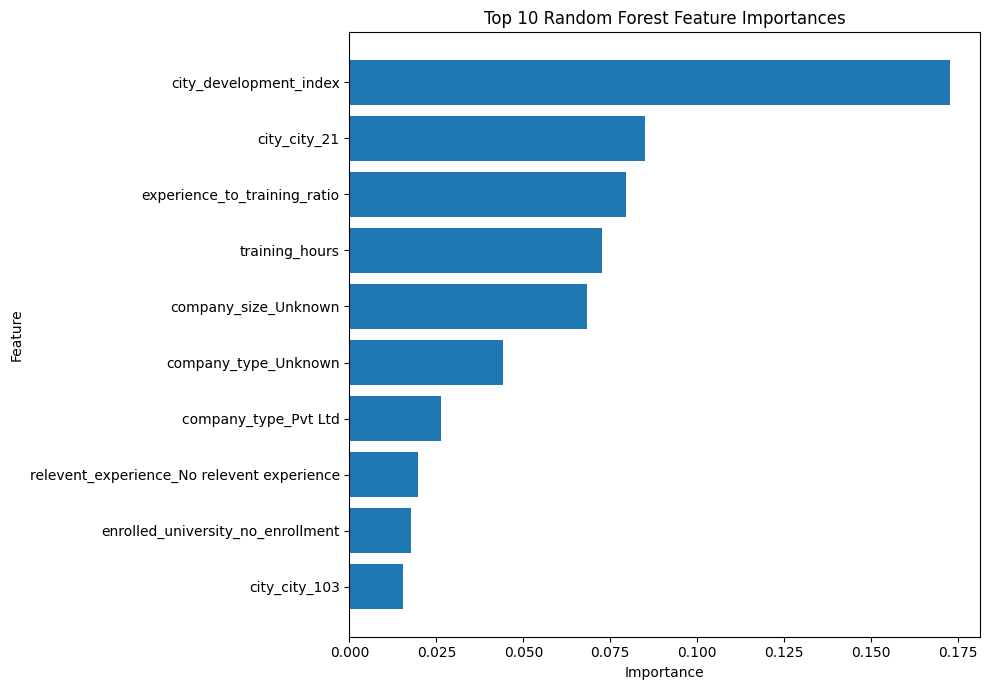

In [ ]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")

plt.tight_layout()
plt.show()

## Tuned Random Forest

In [ ]:
param_grid = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [8, 10, 12, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 3, 4],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [
        "balanced",
        "balanced_subsample",
        None
    ]
}

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf_random = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=25,
    cv=3,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    },
    refit="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_random.fit(X_train_encoded_fe, y_train)

best_rf = rf_random.best_estimator_

print("Best Parameters:")
print(rf_random.best_params_)

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best Parameters:
{'n_estimators': 400, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': 12, 'class_weight': 'balanced_subsample'}


In [ ]:
tuned_pred = best_rf.predict(X_test_encoded_fe)

tuned_accuracy = accuracy_score(y_test, tuned_pred)
tuned_precision = precision_score(y_test, tuned_pred)
tuned_recall = recall_score(y_test, tuned_pred)
tuned_f1 = f1_score(y_test, tuned_pred)

print("Tuned Random Forest Results")
print("-" * 35)
print(f"Accuracy  : {tuned_accuracy:.4f}")
print(f"Precision : {tuned_precision:.4f}")
print(f"Recall    : {tuned_recall:.4f}")
print(f"F1 Score  : {tuned_f1:.4f}")

Tuned Random Forest Results
-----------------------------------
Accuracy  : 0.7978
Precision : 0.5718
Recall    : 0.7508
F1 Score  : 0.6492


In [ ]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1"],
    "Baseline RF": [
        accuracy_score(y_test, baseline_pred),
        precision_score(y_test, baseline_pred),
        recall_score(y_test, baseline_pred),
        f1_score(y_test, baseline_pred)
    ],
    "Tuned RF": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

comparison

,Metric,Baseline RF,Tuned RF
0,Accuracy,0.800104,0.797756
1,Precision,0.576271,0.571770
2,Recall,0.747644,0.750785
3,F1,0.650866,0.649163


Random Forest Using Smote

---
# XGBoost — Tuned Model with Proper Imbalance Handling
Checks whether balancing was applied so far, then builds a tuned XGBoost model on top of the **same cleaning/split/encoding** used above (no re-split, no data leakage).

## Step 12: Check Class Distribution Before Balancing

In [ ]:
print("Class counts in original y_train (before SMOTE):")
print(y_train.value_counts())
print("\nClass proportions in original y_train:")
print(y_train.value_counts(normalize=True).round(3))

imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\nOriginal imbalance ratio (class 0 : class 1) = {imbalance_ratio:.2f} : 1")

print("\n--> Logistic Regression above is trained only on SMOTE-balanced training data.")
print("    XGBoost below uses two imbalance-handling strategies:")
print("    scale_pos_weight (Approach A) and SMOTE (Approach B).")


Class counts in original y_train (before SMOTE):
target
0.0    11504
1.0     3822
Name: count, dtype: int64

Class proportions in original y_train:
target
0.0    0.751
1.0    0.249
Name: proportion, dtype: float64

Original imbalance ratio (class 0 : class 1) = 3.01 : 1

--> Logistic Regression above is trained only on SMOTE-balanced training data.
    XGBoost below uses two imbalance-handling strategies:
    scale_pos_weight (Approach A) and SMOTE (Approach B).


## Step 13: Prepare Data for XGBoost
Reusing the already-fitted `encoder` and the already-split `X_train_encoded` / `X_test_encoded` from Step 6 — just making a working copy and cleaning up column names (XGBoost rejects `<`, `>`, `[`, `]` in feature names, which show up in columns like `experience_<1` or `company_size_<10`).

In [ ]:
import re

def sanitize_columns(cols):
    clean = []
    for c in cols:
        c = c.replace("<", "lt").replace(">", "gt")
        c = re.sub(r"[\[\]{}():,]", "_", c)
        clean.append(c)
    return clean

X_train_xgb = X_train_encoded.copy()
X_test_xgb = X_test_encoded.copy()
X_train_xgb.columns = sanitize_columns(X_train_xgb.columns)
X_test_xgb.columns = sanitize_columns(X_test_xgb.columns)

print("X_train_xgb:", X_train_xgb.shape, " X_test_xgb:", X_test_xgb.shape)

X_train_xgb: (15326, 179)  X_test_xgb: (3832, 179)


## Step 14: XGBoost Approach A — Handle Class Imbalance with `scale_pos_weight`
XGBoost's built-in reweighting: no resampling, no extra rows, no CV-leakage risk — just reweights the loss so mistakes on the minority class cost more during training.

In [ ]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight to use:", round(scale_pos_weight, 3))

scale_pos_weight to use: 3.01


## Step 15: XGBoost Approach A — Hyperparameter Tuning (RandomizedSearchCV, 5-fold Stratified CV)
Searching over the parameters that most affect XGBoost's accuracy/efficiency trade-off: tree depth, learning rate, number of trees, subsampling, and regularization. Scoring on **ROC-AUC** instead of accuracy, since accuracy is misleading on imbalanced classes.

In [ ]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

# Kept intentionally light (small grid, n_iter=10, 3-fold CV) so both Approach A and Approach B
# searches below finish quickly — widen this if you have more compute time available.
param_dist = {
    "n_estimators": [150, 250, 350],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.03, 0.05, 0.08, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.2, 0.4],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [1, 2, 3],
}

base_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",   # fast, memory-efficient histogram-based training
    random_state=42,
    n_jobs=1,
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    base_model,
    param_distributions=param_dist,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=0,
)
search.fit(X_train_xgb, y_train)

print("Best params:", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 4))

Best params: {'subsample': 0.7, 'reg_lambda': 2, 'reg_alpha': 0.1, 'n_estimators': 350, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.2, 'colsample_bytree': 0.8}
Best CV ROC-AUC: 0.7968


## Step 16: XGBoost Approach A — Train the Final Model with Early Stopping
Using the best parameters from the search, with a held-out validation slice and `early_stopping_rounds` so training stops as soon as validation AUC stops improving — this keeps the final model efficient (fewer trees than the max) instead of always training the full `n_estimators`.

In [ ]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_xgb, y_train, test_size=0.15, random_state=42, stratify=y_train
)

best_params = search.best_params_

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30,
    **best_params,
)

xgb_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
print("Stopped at iteration:", xgb_model.best_iteration, "out of", best_params["n_estimators"])

Stopped at iteration: 25 out of 350


## Step 17: XGBoost Approach A — Evaluate the Tuned Model

=== Tuned XGBoost - Metrics ===
Accuracy : 0.7593945720250522
Precision: 0.5110073382254836
Recall   : 0.8020942408376963
F1-score : 0.6242868785656072
ROC-AUC  : 0.8135534215214728

              precision    recall  f1-score   support

         0.0       0.92      0.75      0.82      2877
         1.0       0.51      0.80      0.62       955

    accuracy                           0.76      3832
   macro avg       0.71      0.77      0.72      3832
weighted avg       0.82      0.76      0.77      3832



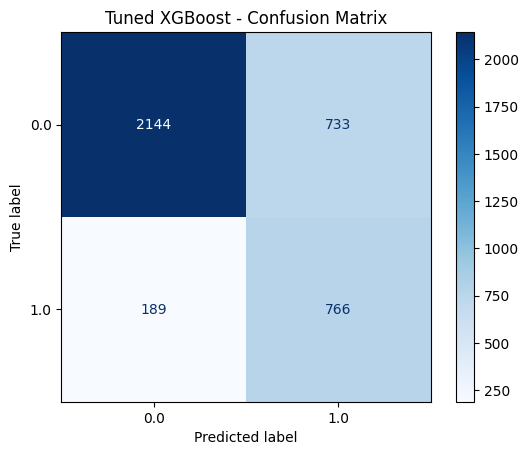

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
)

y_pred_xgb = xgb_model.predict(X_test_xgb)
y_proba_xgb = xgb_model.predict_proba(X_test_xgb)[:, 1]

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_proba_xgb)

print("=== Tuned XGBoost - Metrics ===")
print("Accuracy :", accuracy_xgb)
print("Precision:", precision_xgb)
print("Recall   :", recall_xgb)
print("F1-score :", f1_xgb)
print("ROC-AUC  :", roc_auc_xgb)
print()
print(classification_report(y_test, y_pred_xgb))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb, cmap="Blues")
plt.title("Tuned XGBoost - Confusion Matrix")
plt.show()

## Step 17.1: XGBoost Approach B — Balance with SMOTE
Same idea as Step 6.1, but for XGBoost we have to be more careful about **two leakage points**:
1. **Hyperparameter search (CV):** if we ran SMOTE once on the whole training set before `RandomizedSearchCV`, synthetic points from a training fold could end up looking very similar to real points in that fold's validation split, inflating the CV score. Fix: put SMOTE **inside an `imblearn` Pipeline**, so it's re-fit on only the training portion of each fold.
2. **Early stopping:** the same applies to the train/validation split used for early stopping — SMOTE must only be applied to the train slice, never to the validation slice.

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline

pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        random_state=42,
        n_jobs=1,
    )),
])

param_dist_smote = {f"clf__{k}": v for k, v in param_dist.items()}

search_smote = RandomizedSearchCV(
    pipe,
    param_distributions=param_dist_smote,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=0,
)
search_smote.fit(X_train_xgb, y_train)

print("Best params (Approach B):", search_smote.best_params_)
print("Best CV ROC-AUC (Approach B):", round(search_smote.best_score_, 4))

Best params (Approach B): {'clf__subsample': 0.7, 'clf__reg_lambda': 2, 'clf__reg_alpha': 0, 'clf__n_estimators': 150, 'clf__min_child_weight': 1, 'clf__max_depth': 5, 'clf__learning_rate': 0.08, 'clf__gamma': 0, 'clf__colsample_bytree': 0.6}
Best CV ROC-AUC (Approach B): 0.7956


## Step 17.2: XGBoost Approach B — Train the Final Model

In [ ]:
best_params_smote = {k.replace("clf__", ""): v for k, v in search_smote.best_params_.items()}

# Same real (unbalanced) train/val split as Approach A would use — SMOTE goes ONLY on the train slice
X_tr_b, X_val_b, y_tr_b, y_val_b = train_test_split(
    X_train_xgb, y_train, test_size=0.15, random_state=42, stratify=y_train
)
X_tr_b_bal, y_tr_b_bal = SMOTE(random_state=42).fit_resample(X_tr_b, y_tr_b)

xgb_model_smote = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=42,
    n_jobs=1,
    early_stopping_rounds=30,
    **best_params_smote,
)

# eval_set uses the UNTOUCHED validation slice (real distribution) — not the SMOTE-balanced one
xgb_model_smote.fit(X_tr_b_bal, y_tr_b_bal, eval_set=[(X_val_b, y_val_b)], verbose=False)
print("Stopped at iteration:", xgb_model_smote.best_iteration, "out of", best_params_smote["n_estimators"])

Stopped at iteration: 18 out of 150


## Step 17.3: XGBoost Approach B — Evaluate

=== XGBoost + SMOTE (Approach B) - Metrics ===
Accuracy : 0.7886221294363257
Precision: 0.5587044534412956
Recall   : 0.7225130890052356
F1-score : 0.6301369863013698
ROC-AUC  : 0.8098897739246269


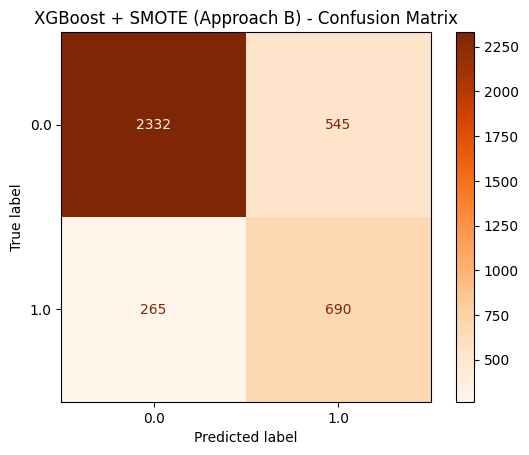

In [ ]:
y_pred_xgb_smote = xgb_model_smote.predict(X_test_xgb)
y_proba_xgb_smote = xgb_model_smote.predict_proba(X_test_xgb)[:, 1]

accuracy_xgb_smote = accuracy_score(y_test, y_pred_xgb_smote)
precision_xgb_smote = precision_score(y_test, y_pred_xgb_smote)
recall_xgb_smote = recall_score(y_test, y_pred_xgb_smote)
f1_xgb_smote = f1_score(y_test, y_pred_xgb_smote)
roc_auc_xgb_smote = roc_auc_score(y_test, y_proba_xgb_smote)

print("=== XGBoost + SMOTE (Approach B) - Metrics ===")
print("Accuracy :", accuracy_xgb_smote)
print("Precision:", precision_xgb_smote)
print("Recall   :", recall_xgb_smote)
print("F1-score :", f1_xgb_smote)
print("ROC-AUC  :", roc_auc_xgb_smote)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb_smote, cmap="Oranges")
plt.title("XGBoost + SMOTE (Approach B) - Confusion Matrix")
plt.show()

## Step 17.4: Compare the Two Balanced XGBoost Approaches
Which balancing method to keep in the final report — `scale_pos_weight` or SMOTE — comes down to comparing these two directly.

           XGBoost + scale_pos_weight  XGBoost + SMOTE
Accuracy                     0.759395         0.788622
Precision                    0.511007         0.558704
Recall                       0.802094         0.722513
F1-score                     0.624287         0.630137


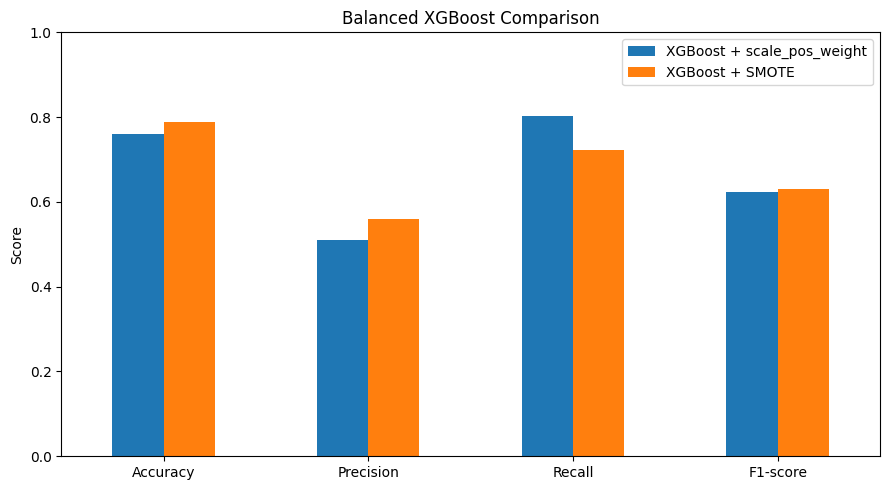

In [ ]:
## Step 17.4: Compare the Two Balanced XGBoost Approaches

comparison = pd.DataFrame({

    "XGBoost + scale_pos_weight": {
        "Accuracy": accuracy_xgb,
        "Precision": precision_xgb,
        "Recall": recall_xgb,
        "F1-score": f1_xgb
    },

    "XGBoost + SMOTE": {
        "Accuracy": accuracy_xgb_smote,
        "Precision": precision_xgb_smote,
        "Recall": recall_xgb_smote,
        "F1-score": f1_xgb_smote
    }

})

print(comparison)

comparison.plot(kind="bar", figsize=(9, 5))

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Balanced XGBoost Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 18: Feature Importance

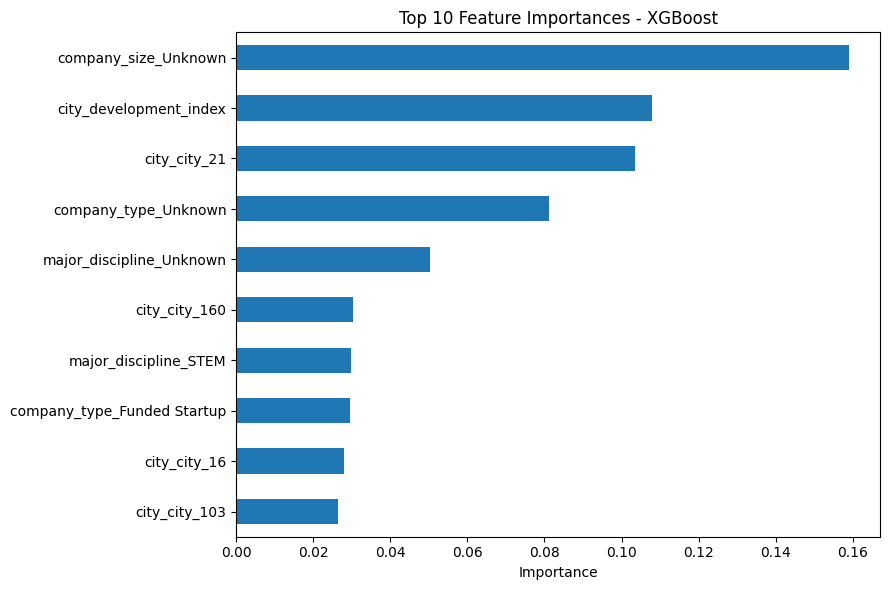

In [ ]:
importances = pd.Series(xgb_model.feature_importances_, index=X_train_xgb.columns)
top_features = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 6))
top_features.sort_values().plot(kind="barh")
plt.title("Top 10 Feature Importances - XGBoost")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Step 19: Compare the Balanced Models


=== Final Model Comparison ===


,KNN,LR + SMOTE,FE LR + SMOTE,Baseline Random Forest,Tuned Random Forest,XGBoost + scale_pos_weight,XGBoost + SMOTE
Accuracy,0.762787,0.772704,0.780271,0.800104,0.797756,0.759395,0.788622
Precision,0.517451,0.530568,0.542196,0.576271,0.571770,0.511007,0.558704
Recall,0.714136,0.763351,0.760209,0.747644,0.750785,0.802094,0.722513
F1-score,0.600088,0.626020,0.632956,0.650866,0.649163,0.624287,0.630137


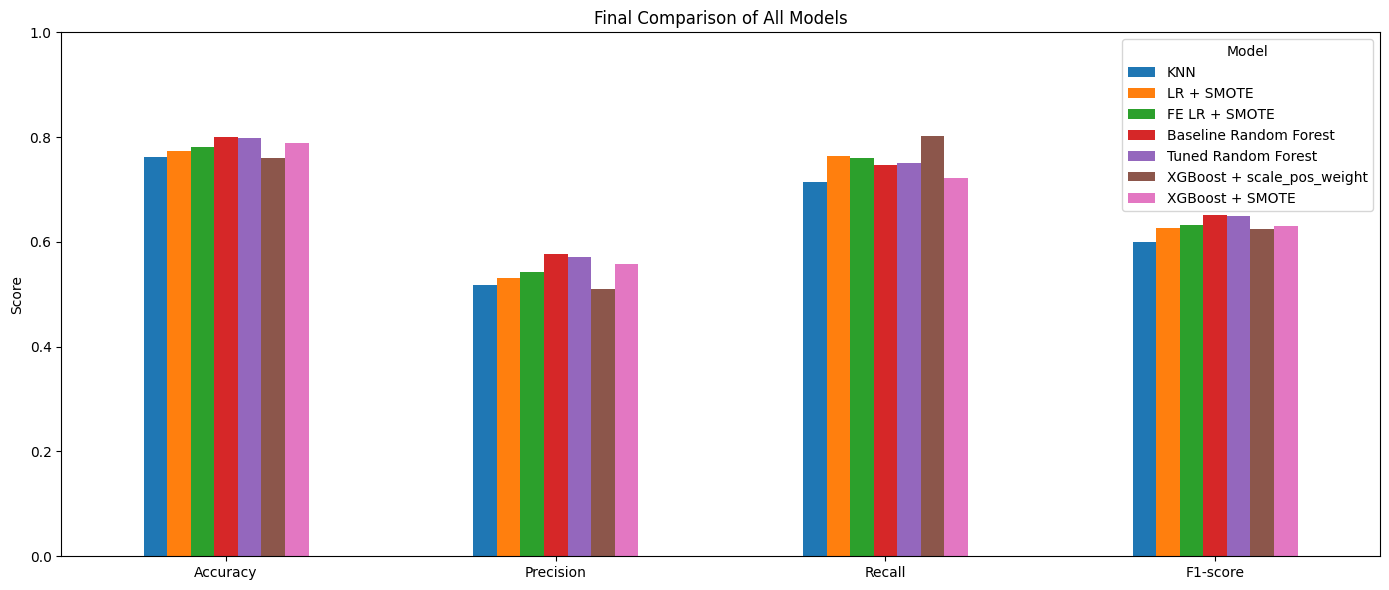

=== Model Ranking by F1-score ===


,Accuracy,Precision,Recall,F1-score
Baseline Random Forest,0.800104,0.576271,0.747644,0.650866
Tuned Random Forest,0.797756,0.571770,0.750785,0.649163
FE LR + SMOTE,0.780271,0.542196,0.760209,0.632956
XGBoost + SMOTE,0.788622,0.558704,0.722513,0.630137
LR + SMOTE,0.772704,0.530568,0.763351,0.626020
XGBoost + scale_pos_weight,0.759395,0.511007,0.802094,0.624287
KNN,0.762787,0.517451,0.714136,0.600088



BEST MODEL FOR DEPLOYMENT
Model    : Baseline Random Forest
Accuracy : 0.8001043841336117
Precision: 0.576271186440678
Recall   : 0.7476439790575916
F1-score : 0.650865998176846


In [ ]:
# ============================================================
# Step 19: Compare All Final Models
# ============================================================

model_comparison = pd.DataFrame({
    "KNN": {
        "Accuracy": accuracy_knn,
        "Precision": precision_knn,
        "Recall": recall_knn,
        "F1-score": f1_knn
    },
    "LR + SMOTE": {
        "Accuracy": accuracy_bal,
        "Precision": precision_bal,
        "Recall": recall_bal,
        "F1-score": f1_bal
    },
    "FE LR + SMOTE": {
        "Accuracy": accuracy_fe_bal,
        "Precision": precision_fe_bal,
        "Recall": recall_fe_bal,
        "F1-score": f1_fe_bal
    },"Baseline Random Forest": {
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1-score": rf_f1
    },
    "Tuned Random Forest": {
        "Accuracy": tuned_accuracy,
        "Precision": tuned_precision,
        "Recall": tuned_recall,
        "F1-score": tuned_f1
    },
    "XGBoost + scale_pos_weight": {
        "Accuracy": accuracy_xgb,
        "Precision": precision_xgb,
        "Recall": recall_xgb,
        "F1-score": f1_xgb
    },
    "XGBoost + SMOTE": {
        "Accuracy": accuracy_xgb_smote,
        "Precision": precision_xgb_smote,
        "Recall": recall_xgb_smote,
        "F1-score": f1_xgb_smote
    }
})

print("=== Final Model Comparison ===")
display(model_comparison)

model_comparison.plot(kind="bar", figsize=(14, 6))
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Final Comparison of All Models")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

# Rank models by F1-score (primary metric for imbalanced classification)
ranking = model_comparison.T.sort_values(by="F1-score", ascending=False)

print("=== Model Ranking by F1-score ===")
display(ranking)

best_model_name = ranking.index[0]

print("\n========================================")
print("BEST MODEL FOR DEPLOYMENT")
print("========================================")
print("Model    :", best_model_name)
print("Accuracy :", ranking.loc[best_model_name, "Accuracy"])
print("Precision:", ranking.loc[best_model_name, "Precision"])
print("Recall   :", ranking.loc[best_model_name, "Recall"])
print("F1-score :", ranking.loc[best_model_name, "F1-score"])


In [ ]:
#Bonus

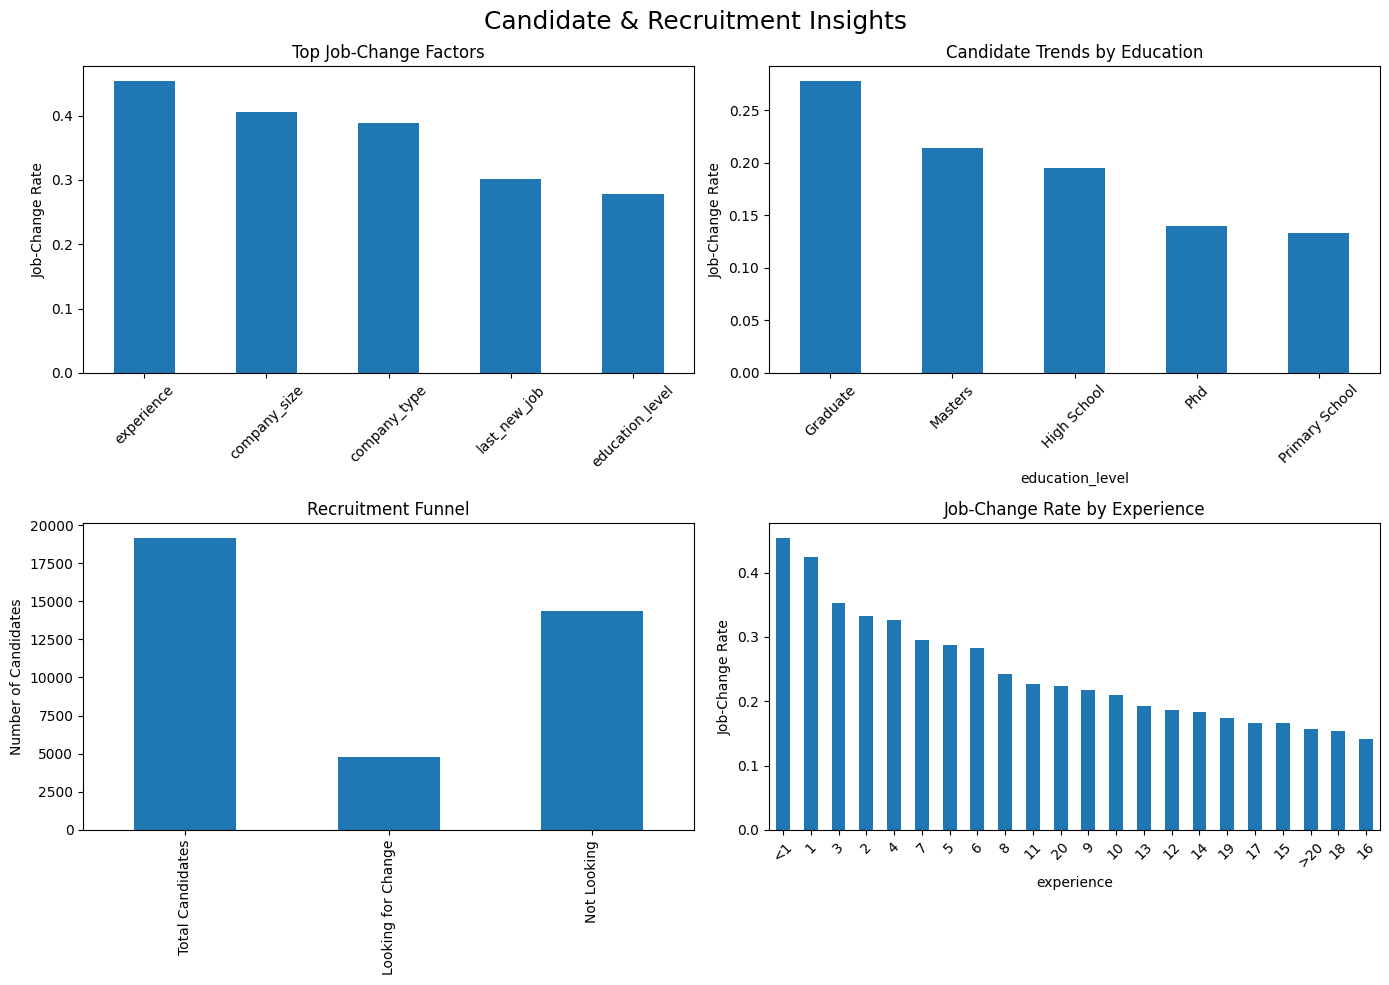

In [ ]:
# Insights Dashboard

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top job-change factors
factors = ["education_level", "experience", "company_size", "company_type", "last_new_job"]

factor_rates = {}

for col in factors:
    factor_rates[col] = df_clean.groupby(col)["target"].mean().max()

pd.Series(factor_rates).sort_values(ascending=False).plot(
    kind="bar", ax=axes[0, 0]
)

axes[0, 0].set_title("Top Job-Change Factors")
axes[0, 0].set_ylabel("Job-Change Rate")
axes[0, 0].tick_params(axis="x", rotation=45)


# Candidate profile trends
df_clean.groupby("education_level")["target"].mean().sort_values(
    ascending=False
).plot(kind="bar", ax=axes[0, 1])

axes[0, 1].set_title("Candidate Trends by Education")
axes[0, 1].set_ylabel("Job-Change Rate")
axes[0, 1].tick_params(axis="x", rotation=45)


# Recruitment funnel
total = len(df_clean)
looking = df_clean["target"].sum()
not_looking = total - looking

pd.Series({
    "Total Candidates": total,
    "Looking for Change": looking,
    "Not Looking": not_looking
}).plot(kind="bar", ax=axes[1, 0])

axes[1, 0].set_title("Recruitment Funnel")
axes[1, 0].set_ylabel("Number of Candidates")


# Experience trends
df_clean.groupby("experience")["target"].mean().sort_values(
    ascending=False
).plot(kind="bar", ax=axes[1, 1])

axes[1, 1].set_title("Job-Change Rate by Experience")
axes[1, 1].set_ylabel("Job-Change Rate")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.suptitle("Candidate & Recruitment Insights", fontsize=18)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Bonus: Top 10 Candidate Shortlist
# ============================================================

# Best-performing model
best_model = baseline_rf

# Prepare all candidates
X_all = df_clean.drop(columns=["target", "enrollee_id"]).copy()

# -----------------------------
# Feature Engineering
# -----------------------------

experience_num_all = (
    X_all["experience"]
    .replace({
        "<1": 0,
        ">20": 21,
        "Unknown": 0
    })
    .astype(float)
)

X_all_fe_num = X_all[numerical_columns].copy()

X_all_fe_num["experience_to_training_ratio"] = (
    experience_num_all / (X_all["training_hours"] + 1)
)

X_all_fe_num["has_relevant_degree"] = (
    X_all["major_discipline"] == "STEM"
).astype(int)

# -----------------------------
# Encoding
# Use the SAME encoder from Step 6
# -----------------------------

X_all_cat = pd.DataFrame(
    encoder.transform(X_all[categorical_columns]),
    index=X_all.index,
    columns=encoder.get_feature_names_out(categorical_columns)
)

# -----------------------------
# Build final feature matrix
# -----------------------------

X_all_encoded_fe = pd.concat(
    [X_all_cat, X_all_fe_num],
    axis=1
)

X_all_encoded_fe.columns = X_all_encoded_fe.columns.astype(str)

# Make sure columns are in exactly the same order
X_all_encoded_fe = X_all_encoded_fe[
    X_train_encoded_fe.columns
]

# -----------------------------
# Predict probabilities
# -----------------------------

probabilities = baseline_rf.predict_proba(
    X_all_encoded_fe
)[:, 1]

# -----------------------------
# Create ranking
# -----------------------------

candidate_ranking = pd.DataFrame({
    "enrollee_id": df_clean["enrollee_id"].values,
    "Job_Change_Probability": (
        probabilities * 100
    ).round(2)
})

# Sort by probability
candidate_ranking = candidate_ranking.sort_values(
    by="Job_Change_Probability",
    ascending=False
).reset_index(drop=True)

# Add rank
candidate_ranking.insert(
    0,
    "Rank",
    range(1, len(candidate_ranking) + 1)
)

# Top 10
top_10 = candidate_ranking.head(10)

print("Top 10 Candidates Most Likely to Change Jobs:")
display(top_10)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Top 10 Candidates Most Likely to Change Jobs:


,Rank,enrollee_id,Job_Change_Probability
0,1,13344,91.46
1,2,29460,90.11
2,3,13186,89.84
3,4,28980,89.74
4,5,17191,89.65
5,6,11042,89.59
6,7,7989,89.57
7,8,15394,89.56
8,9,17969,89.35
9,10,24296,89.21


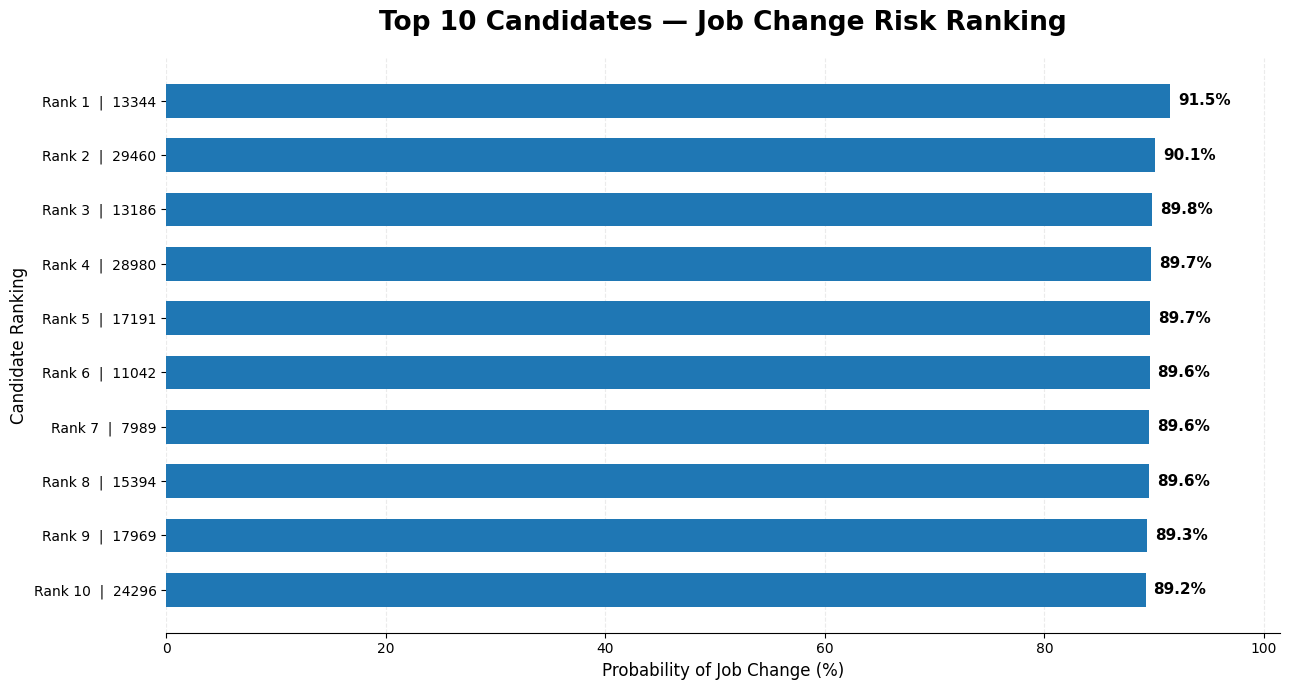

In [ ]:
# ============================================================
# Top 10 Candidate Ranking
# ============================================================

plot_data = top_10.sort_values(
    "Job_Change_Probability",
    ascending=True
).copy()

plot_data["Label"] = (
    "Rank "
    + plot_data["Rank"].astype(str)
    + "  |  "
    + plot_data["enrollee_id"].astype(str)
)

fig, ax = plt.subplots(figsize=(13, 7))

bars = ax.barh(
    plot_data["Label"],
    plot_data["Job_Change_Probability"],
    height=0.62
)

for bar, value in zip(
    bars,
    plot_data["Job_Change_Probability"]
):
    ax.text(
        value + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Top 10 Candidates — Job Change Risk Ranking",
    fontsize=19,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Probability of Job Change (%)",
    fontsize=12
)

ax.set_ylabel(
    "Candidate Ranking",
    fontsize=12
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.set_xlim(
    0,
    plot_data["Job_Change_Probability"].max() + 10
)

plt.tight_layout()
plt.show()

# Deployment: Export ALL 7 Models + Metrics (Multi-Model Dashboard)

In [ ]:
import joblib
import json
import re
import os
import sklearn


def sanitize_columns(cols):
    clean = []
    for c in cols:
        c = c.replace("<", "lt").replace(">", "gt")
        c = re.sub(r"[\[\]{}():,]", "_", c)
        clean.append(c)
    return clean


model_registry = {
    "KNN": {"estimator": best_knn, "feature_type": "plain", "threshold": float(best_threshold),
            "metrics": {"accuracy": accuracy_knn, "precision": precision_knn, "recall": recall_knn, "f1": f1_knn},
            "heavy": False},
    "LR + SMOTE": {"estimator": model_bal, "feature_type": "plain", "threshold": 0.5,
            "metrics": {"accuracy": accuracy_bal, "precision": precision_bal, "recall": recall_bal, "f1": f1_bal},
            "heavy": False},
    "FE LR + SMOTE": {"estimator": model_fe_bal, "feature_type": "fe", "threshold": 0.5,
            "metrics": {"accuracy": accuracy_fe_bal, "precision": precision_fe_bal, "recall": recall_fe_bal, "f1": f1_fe_bal},
            "heavy": False},
    "Baseline Random Forest": {"estimator": baseline_rf, "feature_type": "fe", "threshold": 0.5,
            "metrics": {"accuracy": rf_accuracy, "precision": rf_precision, "recall": rf_recall, "f1": rf_f1},
            "heavy": False},
    "Tuned Random Forest": {"estimator": best_rf, "feature_type": "fe", "threshold": 0.5,
            "metrics": {"accuracy": tuned_accuracy, "precision": tuned_precision, "recall": tuned_recall, "f1": tuned_f1},
            "heavy": False},
    "XGBoost + scale_pos_weight": {"estimator": xgb_model, "feature_type": "xgb", "threshold": 0.5,
            "metrics": {"accuracy": accuracy_xgb, "precision": precision_xgb, "recall": recall_xgb, "f1": f1_xgb},
            "heavy": True},
    "XGBoost + SMOTE": {"estimator": xgb_model_smote, "feature_type": "xgb", "threshold": 0.5,
            "metrics": {"accuracy": accuracy_xgb_smote, "precision": precision_xgb_smote, "recall": recall_xgb_smote, "f1": f1_xgb_smote},
            "heavy": True},
}

# The xgboost PACKAGE itself (not the small pickle files) is what blows past Vercel's 500 MB
# limit. Only ever load an XGBoost model live if it is actually the winner - and only that
# one variant, never both.

needs_xgboost_live = best_model_name in ("XGBoost + scale_pos_weight", "XGBoost + SMOTE")
import shutil
shutil.rmtree("models", ignore_errors=True)  # يمسح أي بواقي من محاولة سابقة

os.makedirs("models", exist_ok=True)

model_files = {}
for name, info in model_registry.items():
    is_live = (not info["heavy"]) or (name == best_model_name)
    if not is_live:
        continue
    safe_name = re.sub(r"[^a-zA-Z0-9]+", "_", name).strip("_").lower()
    filename = f"models/{safe_name}.pkl"
    joblib.dump(info["estimator"], filename, compress=3)
    model_files[name] = filename

joblib.dump(encoder, "encoder.pkl")

feature_orders = {
    "plain": list(X_train_encoded.columns),
    "fe": list(X_train_encoded_fe.columns),
    "xgb": sanitize_columns(list(X_train_encoded.columns)),
}

metadata = {
    "best_model_name": best_model_name,
    "categorical_columns": categorical_columns,
    "numerical_columns": numerical_columns,
    "feature_orders": feature_orders,
    "needs_xgboost_live": needs_xgboost_live,
    "models": {
        name: {
            "file": model_files.get(name),
            "feature_type": info["feature_type"],
            "threshold": info["threshold"],
            "metrics": {k: float(v) for k, v in info["metrics"].items()},
            "live": name in model_files,
        }
        for name, info in model_registry.items()
    },
}

with open("metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Live models (loaded for /predict):", list(model_files.keys()))
print("Metrics-only models (in /metrics chart, NOT live-scored):",
      [n for n in model_registry if n not in model_files])
print()

total_mb = os.path.getsize("encoder.pkl") / (1024 * 1024)
for name, path in model_files.items():
    size_mb = os.path.getsize(path) / (1024 * 1024)
    total_mb += size_mb
    print(f"  {name:32s} -> {path}  ({size_mb:.1f} MB)")
print(f"\nTotal size of all LIVE model files: {total_mb:.1f} MB")
print("Best model                 :", best_model_name)
print("xgboost needed in requirements.txt:", needs_xgboost_live)


Live models (loaded for /predict): ['KNN', 'LR + SMOTE', 'FE LR + SMOTE', 'Baseline Random Forest', 'Tuned Random Forest']
Metrics-only models (in /metrics chart, NOT live-scored): ['XGBoost + scale_pos_weight', 'XGBoost + SMOTE']

  KNN                              -> models/knn.pkl  (2.0 MB)
  LR + SMOTE                       -> models/lr_smote.pkl  (0.0 MB)
  FE LR + SMOTE                    -> models/fe_lr_smote.pkl  (0.0 MB)
  Baseline Random Forest           -> models/baseline_random_forest.pkl  (12.8 MB)
  Tuned Random Forest              -> models/tuned_random_forest.pkl  (8.5 MB)

Total size of all LIVE model files: 23.4 MB
Best model                 : Baseline Random Forest
xgboost needed in requirements.txt: False


## Sanity Check — Run All 7 Models on One Row

In [ ]:
import joblib, json, re
import pandas as pd

loaded_encoder = joblib.load("encoder.pkl")
with open("metadata.json") as f:
    meta = json.load(f)

loaded_models = {name: joblib.load(info["file"]) for name, info in meta["models"].items() if info["live"]}


def sanitize_columns(cols):
    clean = []
    for c in cols:
        c = c.replace("<", "lt").replace(">", "gt")
        c = re.sub(r"[\[\]{}():,]", "_", c)
        clean.append(c)
    return clean


def build_all_feature_sets(raw_df, meta, encoder):
    cat_encoded = pd.DataFrame(
        encoder.transform(raw_df[meta["categorical_columns"]]),
        columns=encoder.get_feature_names_out(meta["categorical_columns"]),
        index=raw_df.index,
    )

    plain = pd.concat([cat_encoded, raw_df[meta["numerical_columns"]]], axis=1)
    plain.columns = plain.columns.astype(str)
    plain = plain.reindex(columns=meta["feature_orders"]["plain"], fill_value=0)

    exp_num = raw_df["experience"].replace({"<1": 0, ">20": 21, "Unknown": 0}).astype(float)
    fe_num = raw_df[meta["numerical_columns"]].copy()
    fe_num["experience_to_training_ratio"] = exp_num / (raw_df["training_hours"] + 1)
    fe_num["has_relevant_degree"] = (raw_df["major_discipline"] == "STEM").astype(int)
    fe = pd.concat([cat_encoded, fe_num], axis=1)
    fe.columns = fe.columns.astype(str)
    fe = fe.reindex(columns=meta["feature_orders"]["fe"], fill_value=0)

    xgb = plain.copy()
    xgb.columns = sanitize_columns(xgb.columns)
    xgb = xgb.reindex(columns=meta["feature_orders"]["xgb"], fill_value=0)

    return {"plain": plain, "fe": fe, "xgb": xgb}


sample = X_test.iloc[[0]]
feature_sets = build_all_feature_sets(sample, meta, loaded_encoder)

print("Actual target:", y_test.iloc[0], "(1 = looking for a job change, 0 = not looking)\n")
for name, info in meta["models"].items():
    marker = "  <-- BEST" if name == meta["best_model_name"] else ""
    if not info["live"]:
        print(f"{name:32s} (not live - metrics-only){marker}")
        continue
    model = loaded_models[name]
    X_input = feature_sets[info["feature_type"]]
    proba_change = model.predict_proba(X_input)[0][1]
    predicted = "Likely to Change Jobs" if proba_change >= info["threshold"] else "Likely to Stay"
    print(f"{name:32s} {proba_change:.3f}  {predicted}{marker}")


Actual target: 0.0 (1 = looking for a job change, 0 = not looking)

KNN                              0.116  Likely to Stay
LR + SMOTE                       0.096  Likely to Stay
FE LR + SMOTE                    0.092  Likely to Stay
Baseline Random Forest           0.107  Likely to Stay  <-- BEST
Tuned Random Forest              0.165  Likely to Stay
XGBoost + scale_pos_weight       (not live - metrics-only)
XGBoost + SMOTE                  (not live - metrics-only)


## Generate the FastAPI Backend (`main.py`)

In [ ]:
%%writefile main.py
from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import pandas as pd
import json
import re

app = FastAPI(title="Career / Job-Change Prediction API (Multi-Model)")

encoder = joblib.load("encoder.pkl")
with open("metadata.json") as f:
    meta = json.load(f)

models = {name: joblib.load(info["file"]) for name, info in meta["models"].items() if info["live"]}
categorical_columns = meta["categorical_columns"]
numerical_columns = meta["numerical_columns"]
feature_orders = meta["feature_orders"]
best_model_name = meta["best_model_name"]


def sanitize_columns(cols):
    clean = []
    for c in cols:
        c = c.replace("<", "lt").replace(">", "gt")
        c = re.sub(r"[\[\]{}():,]", "_", c)
        clean.append(c)
    return clean


class Candidate(BaseModel):
    city: str
    gender: str
    relevent_experience: str
    enrolled_university: str
    education_level: str
    major_discipline: str
    experience: str
    company_size: str
    company_type: str
    last_new_job: str
    city_development_index: float
    training_hours: float


def build_feature_sets(raw: pd.DataFrame):
    cat_encoded = pd.DataFrame(
        encoder.transform(raw[categorical_columns]),
        columns=encoder.get_feature_names_out(categorical_columns),
    )

    plain = pd.concat([cat_encoded, raw[numerical_columns]], axis=1)
    plain.columns = plain.columns.astype(str)
    plain = plain.reindex(columns=feature_orders["plain"], fill_value=0)

    exp_num = raw["experience"].replace({"<1": 0, ">20": 21, "Unknown": 0}).astype(float)
    fe_num = raw[numerical_columns].copy()
    fe_num["experience_to_training_ratio"] = exp_num / (raw["training_hours"] + 1)
    fe_num["has_relevant_degree"] = (raw["major_discipline"] == "STEM").astype(int)
    fe = pd.concat([cat_encoded, fe_num], axis=1)
    fe.columns = fe.columns.astype(str)
    fe = fe.reindex(columns=feature_orders["fe"], fill_value=0)

    xgb = plain.copy()
    xgb.columns = sanitize_columns(xgb.columns)
    xgb = xgb.reindex(columns=feature_orders["xgb"], fill_value=0)

    return {"plain": plain, "fe": fe, "xgb": xgb}


@app.get("/")
def root():
    return {"status": "API is running", "best_model": best_model_name, "live_models": list(models.keys())}


@app.get("/metrics")
def metrics():
    # Static training-time numbers for ALL 7 models, regardless of which are live.
    return {name: info["metrics"] for name, info in meta["models"].items()}


@app.post("/predict")
def predict(candidate: Candidate):
    raw = pd.DataFrame([candidate.dict()])
    feature_sets = build_feature_sets(raw)

    results = {}
    for name, info in meta["models"].items():
        if not info["live"]:
            results[name] = {"available": False}
            continue
        model = models[name]
        X_input = feature_sets[info["feature_type"]]
        proba_change = float(model.predict_proba(X_input)[0][1])
        will_change = proba_change >= info["threshold"]
        results[name] = {
            "available": True,
            "job_change_probability": round(proba_change, 4),
            "stay_probability": round(1 - proba_change, 4),
            "label": "Likely to Change Jobs" if will_change else "Likely to Stay",
        }

    return {
        "best_model": best_model_name,
        "best_result": results[best_model_name],
        "all_models": results,
    }


Overwriting main.py


## Generate `requirements.txt`

In [ ]:
import sklearn
import json

with open("metadata.json") as f:
    _meta_check = json.load(f)

req_lines = [
    "fastapi",
    "uvicorn",
    f"scikit-learn=={sklearn.__version__}",
    "pandas",
    "joblib",
    "pydantic",
    "imbalanced-learn",
]
if _meta_check["needs_xgboost_live"]:
    req_lines.append("xgboost")

with open("requirements.txt", "w") as f:
    f.write("\n".join(req_lines) + "\n")

print("requirements.txt:")
print("\n".join(req_lines))


requirements.txt:
fastapi
uvicorn
scikit-learn==1.6.1
pandas
joblib
pydantic
imbalanced-learn
